# Driver Safety Risk Intelligence
### Independent data science portfolio case study | Synthetic data

**Business question:** Can historical driver indicators help prioritize safety reviews when review capacity is limited?

**Important:** All records and outcomes in this notebook are **synthetically generated**. This work is not affiliated with Foley or any employer. Relationships and measured performance reflect the assumptions used to generate the data, not evidence about actual drivers.

**Workflow:** generate data → explore → preprocess → compare models → holdout evaluation → calibration → operational prioritization → recommendations.

## 1. Environment and imports
Run all cells in order. The notebook creates `data/` and `outputs/` alongside itself.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

p = Path.cwd()
for folder in ('data', 'outputs', 'sql'):
    (p / folder).mkdir(exist_ok=True)

## 2. Generate synthetic data
We simulate 6,500 drivers. Mileage is lognormal, prior violation counts are Poisson, and future incidents are sampled from an explicitly defined logistic risk function. **These are illustrative modeling assumptions, not empirical driver-safety findings.**

In [2]:
rng = np.random.default_rng(20261115)
n = 6500
miles = np.clip(rng.lognormal(10.1, 0.48, n), 3000, 110000).round().astype(int)
experience = rng.integers(0, 31, n)
viol = rng.poisson(0.35 + 0.000006 * miles + 0.3 * (experience < 3))
prior = rng.binomial(1, np.clip(0.05 + 0.06 * viol + 0.05 * (experience < 3), 0, 0.7))
training = rng.binomial(1, 0.62, n)
region = rng.choice(['Northeast', 'South', 'Midwest', 'West'], n)
fleet = rng.choice(['Small', 'Medium', 'Large'], n, p=[0.3, 0.4, 0.3])
compliance = rng.poisson(0.2 + 0.14 * viol + 0.1 * prior)
logit = (-3.7 + 0.42 * viol + 0.85 * prior + 0.22 * compliance
         + 0.000013 * miles - 0.018 * experience - 0.27 * training
         + 0.18 * (region == 'South'))
prob = 1 / (1 + np.exp(-logit))
outcome = rng.binomial(1, prob)
df = pd.DataFrame({
    'driver_id': [f'D{i:05d}' for i in range(n)],
    'annual_miles': miles, 'years_experience': experience,
    'prior_violations': viol, 'prior_incident': prior,
    'compliance_events': compliance, 'completed_training': training,
    'region': region, 'fleet_size': fleet,
    'future_12m_incident': outcome
})
df.to_csv(p / 'data' / 'synthetic_driver_data.csv', index=False)
df.head()

,driver_id,annual_miles,years_experience,prior_violations,prior_incident,compliance_events,completed_training,region,fleet_size,future_12m_incident
0,D00000,24546,28,0,0,0,0,Northeast,Small,0
1,D00001,21961,30,1,0,0,1,Northeast,Small,0
2,D00002,12188,6,0,1,0,1,Northeast,Large,0
3,D00003,19045,28,0,0,0,0,Midwest,Large,0
4,D00004,16545,6,0,0,0,1,Midwest,Medium,0


## 3. Exploratory analysis and data quality
Inspect class balance, missingness, and summary statistics. The original synthetic generator does not add missing values, so imputation is included as a production-oriented pattern rather than a demonstrated necessity.

In [3]:
print('Rows:', len(df))
print('Incident rate:', f"{df['future_12m_incident'].mean():.2%}")
print('Missing values:', df.isna().sum().sum())
display(df.describe(include='all').T)

Rows: 6500
Incident rate: 4.18%
Missing values: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
driver_id,6500,6500,D00000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_miles,6500.0,NaN,NaN,NaN,27475.857692,13799.067829,4451.0,17657.75,24375.0,34268.25,110000.0
years_experience,6500.0,NaN,NaN,NaN,14.991385,8.933216,0.0,7.0,15.0,23.0,30.0
prior_violations,6500.0,NaN,NaN,NaN,0.555692,0.76273,0.0,0.0,0.0,1.0,6.0
prior_incident,6500.0,NaN,NaN,NaN,0.084769,0.278559,0.0,0.0,0.0,0.0,1.0
compliance_events,6500.0,NaN,NaN,NaN,0.295231,0.552861,0.0,0.0,0.0,1.0,4.0
completed_training,6500.0,NaN,NaN,NaN,0.621231,0.485118,0.0,0.0,1.0,1.0,1.0
region,6500,4,West,1681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fleet_size,6500,3,Medium,2612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
future_12m_incident,6500.0,NaN,NaN,NaN,0.041846,0.200253,0.0,0.0,0.0,0.0,1.0


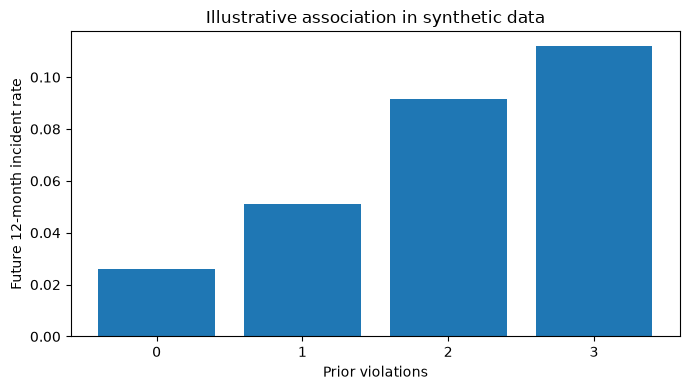

In [4]:
rates = df.groupby('prior_violations')['future_12m_incident'].agg(['mean', 'count'])
rates = rates[rates['count'] >= 30]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rates.index.astype(str), rates['mean'])
ax.set(xlabel='Prior violations', ylabel='Future 12-month incident rate',
       title='Illustrative association in synthetic data')
fig.tight_layout()
fig.savefig(p / 'outputs' / 'risk_by_violations.png', dpi=160)
plt.show()

## 4. Split data and define preprocessing
Use a stratified 60/20/20 split. This is suitable for a synthetic cross-sectional demonstration; a real deployment should use chronological, driver-aware validation and confirm that all predictors are available before the prediction date.

In [5]:
features = [c for c in df if c not in ['driver_id', 'future_12m_incident']]
cat = ['region', 'fleet_size']
num = [c for c in features if c not in cat]
train, temp = train_test_split(df, test_size=0.4, random_state=42,
                               stratify=df.future_12m_incident)
valid, test = train_test_split(temp, test_size=0.5, random_state=42,
                               stratify=temp.future_12m_incident)
print('Train / validation / test:', len(train), len(valid), len(test))

def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)
    ])

Train / validation / test: 3900 1300 1300


## 5. Compare candidate models
Logistic regression provides an interpretable baseline; histogram gradient boosting allows nonlinear relationships. Choose by **validation average precision**, not test performance.

In [6]:
models = {
    'Logistic regression': Pipeline([
        ('prep', make_preprocessor()),
        ('model', LogisticRegression(max_iter=1000))]),
    'Gradient boosting': Pipeline([
        ('prep', make_preprocessor()),
        ('model', HistGradientBoostingClassifier(
            max_iter=110, max_leaf_nodes=10, l2_regularization=5, random_state=42))])
}
val_scores, fitted = {}, {}
for name, candidate in models.items():
    candidate.fit(train[features], train.future_12m_incident)
    fitted[name] = candidate
    val_pred = candidate.predict_proba(valid[features])[:, 1]
    val_scores[name] = average_precision_score(valid.future_12m_incident, val_pred)
display(pd.DataFrame({'validation_average_precision': val_scores}).sort_values(
    'validation_average_precision', ascending=False))

,validation_average_precision
Logistic regression,0.084224
Gradient boosting,0.082415


## 6. Evaluate the selected model on untouched test data
ROC-AUC evaluates ranking, average precision focuses on positive-case retrieval, and Brier score evaluates probability accuracy. The top-20% policy illustrates limited review capacity, not demonstrated incident prevention.

In [7]:
selected = max(val_scores, key=val_scores.get)
model = fitted[selected]
pred = model.predict_proba(test[features])[:, 1]
y = test.future_12m_incident.to_numpy()
threshold = np.quantile(pred, 0.8)
flag = pred >= threshold
metrics = {
    'data_type': 'synthetic', 'n_records': n,
    'event_rate': round(float(df.future_12m_incident.mean()), 4),
    'selected_model': selected,
    'selection_criterion': 'validation average precision',
    'test_roc_auc': round(float(roc_auc_score(y, pred)), 3),
    'test_pr_auc': round(float(average_precision_score(y, pred)), 3),
    'test_brier': round(float(brier_score_loss(y, pred)), 3),
    'top_20pct_recall': round(float(y[flag].sum() / y.sum()), 3),
    'top_20pct_precision': round(float(y[flag].mean()), 3),
    'test_n': len(y)
}
(p / 'outputs' / 'metrics.json').write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))

{
  "data_type": "synthetic",
  "n_records": 6500,
  "event_rate": 0.0418,
  "selected_model": "Logistic regression",
  "selection_criterion": "validation average precision",
  "test_roc_auc": 0.698,
  "test_pr_auc": 0.143,
  "test_brier": 0.038,
  "top_20pct_recall": 0.463,
  "top_20pct_precision": 0.096,
  "test_n": 1300
}


## 7. Calibration by predicted-risk decile
Compare mean predicted probabilities against observed rates. Small sample sizes and synthetic data limit conclusions about operational calibration.

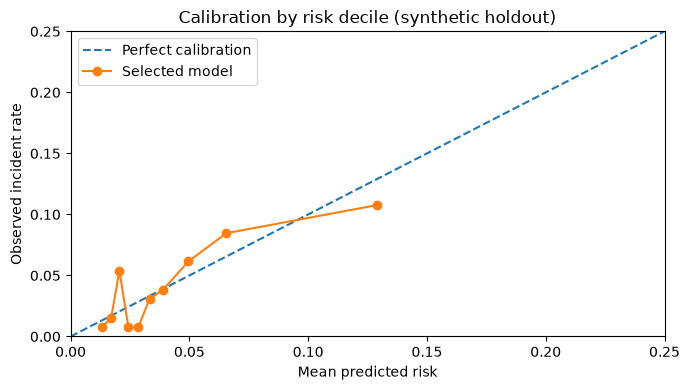

In [8]:
bins = pd.qcut(pred, 10, labels=False, duplicates='drop')
agg = pd.DataFrame({'bin': bins, 'p': pred, 'y': y}).groupby('bin').agg(
    predicted=('p', 'mean'), observed=('y', 'mean'))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([0, 1], [0, 1], '--', label='Perfect calibration')
ax.plot(agg.predicted, agg.observed, 'o-', label='Selected model')
ax.set(xlabel='Mean predicted risk', ylabel='Observed incident rate',
       title='Calibration by risk decile (synthetic holdout)',
       xlim=(0, max(0.25, agg.predicted.max() * 1.1)),
       ylim=(0, max(0.25, agg.observed.max() * 1.1)))
ax.legend()
fig.tight_layout()
fig.savefig(p / 'outputs' / 'calibration.png', dpi=160)
plt.show()

## 8. Operational prioritization
A capacity-constrained safety team could review the top 20% of predicted risks. Compare this policy to random selection using **test-set** incidence capture. This is a descriptive ranking exercise; it does not estimate causal effects or financial ROI.

In [9]:
capture = float(y[flag].sum() / y.sum())
review_share = float(flag.mean())
print(f'Review share: {review_share:.1%}')
print(f'Incidents in reviewed group: {capture:.1%}')
print(f'Capture lift versus random allocation (descriptive): {capture / review_share:.2f}x')

Review share: 20.0%
Incidents in reviewed group: 46.3%
Capture lift versus random allocation (descriptive): 2.31x


## 9. Executive recommendation and limitations
**Illustrative recommendation:** Use risk ranking to design a small, human-reviewed pilot for prioritizing driver safety outreach. Before any production use, validate on real consented and appropriately governed data, evaluate chronological generalization and subgroup error rates, document lawful use and potential fairness impacts, and measure intervention effects through a properly designed experiment.

**Limitations:** The outcome was generated using a hand-specified logistic formula; model performance is largely a consequence of that construction. Region-specific assumptions are artificial. A model identifying higher-risk drivers does not prove that acting on predictions reduces incidents. No claim of real-world efficacy or ROI is made.

**Suggested next steps:** (1) define an intervention and review cost, (2) confirm historical feature availability, (3) assess leakage and data rights, (4) test temporal stability, (5) assess fairness and calibration, (6) conduct a controlled pilot.